# Scenario: A fitness trainer wants to check whether a 4-week running program improves the running performance of 8 students.

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t,ttest_rel

In [22]:
before = [30, 32, 28, 35, 31, 33, 29, 34]

after = [27, 29, 27, 31, 29, 30, 26, 30]
df = pd.DataFrame({"Before" : before,"After":after})
df

,Before,After
0,30,27
1,32,29
2,28,27
3,35,31
4,31,29
5,33,30
6,29,26
7,34,30


In [23]:
mean_before  = df["Before"].mean()
mean_after = df["After"].mean()
sample_size = 8
DOF = sample_size - 1
alpha = 0.05
print("Before mean : ",mean_before)
print("after mean : ",mean_after)
print("sample size : ",sample_size)
print("Degree of freedom : ",DOF)
print("Significance level : ",alpha)

Before mean :  31.5
after mean :  28.625
sample size :  8
Degree of freedom :  7
Significance level :  0.05


In [24]:
t_test_stat ,p_value = ttest_rel(df["Before"],df["After"])
print("t test stats : ",t_test_stat,"\n","p value : ",p_value)

t test stats :  8.205319782145772 
 p value :  7.750455893228257e-05


In [25]:
# critical value 
critical_value = t._ppf(alpha,DOF)
lowerfence = -critical_value
print(critical_value)

-1.8945786050900066


In [26]:
if p_value < alpha:
    print("Decision : we reject the null hypothesis .")
    print("conclusion : there is sufficent evidence at  5 % signifcance level . ")
else :
    print("Decision : we are fail to reject the null hypothesis .")
    print("conclusion : there are not suffiecent evidence at 5 % significane level .")

Decision : we reject the null hypothesis .
conclusion : there is sufficent evidence at  5 % signifcance level . 


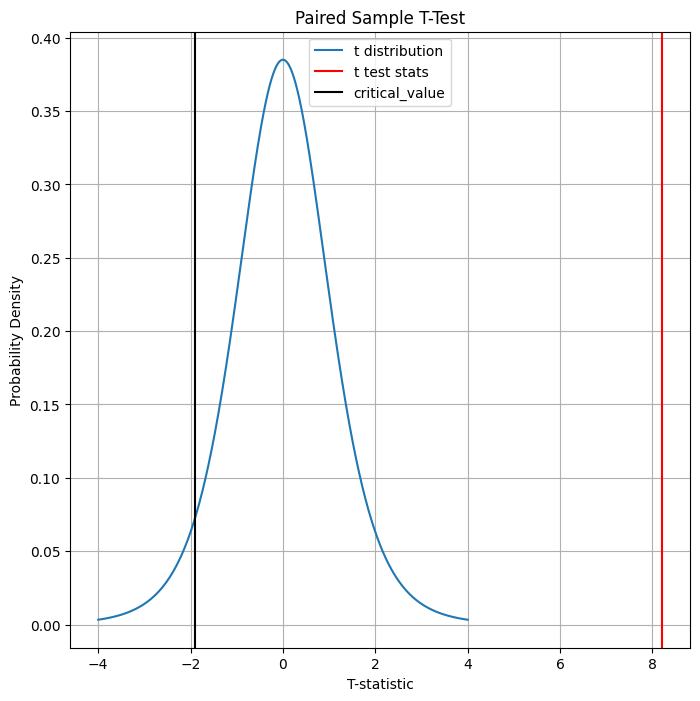

In [28]:
x = np.linspace(-4,4,1000)
y = t._pdf(x,DOF)
plt.figure(figsize=(8,8))
plt.plot(x,y,label = "t distribution")
plt.axvline(t_test_stat,color= "red",label = "t test stats")
plt.axvline(critical_value,color = "black",label = "critical_value")
plt.title("Paired Sample T-Test")
plt.xlabel("T-statistic")
plt.ylabel("Probability Density")
plt.legend()
plt.grid()
plt.show()
